In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
from colour import Color

import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [ ]:
fig, ax = plt.subplots()

ax.set_xlim([0, 10])
scat = ax.scatter(1, 0)
x = np.linspace(0, 10, 1000)
print(len(x))



def animate(i):
    scat.set_offsets((x[i], 0))
    return (scat,)


ani = animation.FuncAnimation(fig, animate, repeat_delay=3000, repeat=True, frames=len(x) - 1, interval=1000//60)



#plt.show()


# To save the animation using Pillow as a gif

os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save('test3.gif', writer=writer)

## Just testing again

In [ ]:
animation_name = 'ani_acoustic'

fig, ax = plt.subplots()


imax=100
Time = np.linspace(-100, 3000, 1000)
A_th = 1
tau_th = 500


A_ac = 0.3
tau_ac = 200
T_ac = 40
phi_ac = 0


ax.set_ylim((-0.2, 1.1*(A_th+A_ac)))
scat = ax.plot(Time, Osc1(Time, A_ac, tau_ac, T_ac, phi_ac ),color='blue')

x = np.linspace(0, 10, 1000)
x =range(0, imax)
print(len(x))




def animate_dtt(i) :

    coeff = (imax-i)/imax
    ax.cla()
    ax.set_ylim((-0.2, 1.1*(A_th+A_ac)))
    scat = ax.plot(Time, np.array(Time>0)*(ExpDec1(Time,coeff*A_th,tau_th) + Osc1(Time, coeff*A_ac, tau_ac, T_ac, phi_ac )), color='blue')

    return(scat,)



#interval=1000//60
ani_dtt = animation.FuncAnimation(fig, animate_dtt, repeat=True, frames=imax, interval = 500)
plt.show()




os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani_dtt.save(animation_name + '.gif', writer=writer)

plt.clf()


In [ ]:
animation_name = 'DTT_signal_thermic'

fig, ax = plt.subplots()


imax=100

top_lim = 3
bottom_limit  = -0.5
Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.3
tau = 800/3

delta_Ec =0.1

#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0

ax.set_ylim(top= top_lim, bottom=bottom_limit)
ax.set_xlim((-350, 1100))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks

plt.xlabel('Energy (u.a.)')
plt.ylabel(r'$\sigma_{ext} (u.a.)')

scat = ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')



Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
 
    coeff = (imax-i)/imax
    ax.cla()

    x_probe = Energy[400]

    
    index_color = int(imax * (1- np.array(Time>0)[i]*(ExpDec1(Time[i], 1, tau)))-0.001)
    
    ax.set_ylim(top= top_lim, bottom=bottom_limit)
    ax.set_xlim((-350, 1100))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('Time (u.a.)')
    ax.set_ylabel(r'$\Delta \sigma_{ext}$ (u.a.)')

    rect_disk = mpatches.Rectangle((0.65, 0.8), 0.2, 0.1, transform=ax.transAxes, facecolor=Colors[index_color].rgb, edgecolor='black')
    ax.add_patch(rect_disk)

    rect_sub = mpatches.Rectangle((0.55, 0.65), 0.4, 0.15, transform=ax.transAxes, facecolor='cyan',alpha=0.5, edgecolor='black')
    ax.add_patch(rect_sub)
    
    
    scat = ax.plot(Time[:i+1], Lorentz(x_probe, E_c+np.array(Time>0)[:i+1]*(ExpDec1(Time[:i+1], delta_Ec, tau)), w + np.array(Time>0)[:i+1]*ExpDec1(Time[:i+1], delta_w, tau), A, y0) - Lorentz(x_probe, E_c, w , A, y0),color='green')

 



    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()

In [ ]:
animation_name = 'Thermic_variation_SPR'

fig, ax = plt.subplots()


imax=100

top_lim = 6

ymin, ymax = 0,  6


Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.3
tau = 800/3

delta_Ec =0.1

#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0

ax.set_ylim((ymin, ymax))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks

plt.xlabel('Energy (u.a.)')
plt.ylabel(r'$\sigma_{ext} (u.a.)')

scat = ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')



Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :

    coeff = (imax-i)/imax
    ax.cla()

    x_probe = Energy[400]

    
    index_color = int(imax * (1- np.array(Time>0)[i]*(ExpDec1(Time[i], 1, tau)))-0.001)
    
    ax.set_ylim((ymin, ymax))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('Energy (u.a.)')
    ax.set_ylabel(r'$\sigma_{ext}$ (u.a.)')

    rect_disk = mpatches.Rectangle((0.65, 0.8), 0.2, 0.1, transform=ax.transAxes, facecolor=Colors[index_color].rgb, edgecolor='black')
    ax.add_patch(rect_disk)

    rect_sub = mpatches.Rectangle((0.55, 0.65), 0.4, 0.15, transform=ax.transAxes, facecolor='cyan',alpha=0.5, edgecolor='black')
    ax.add_patch(rect_sub)
    scat = ax.plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*(ExpDec1(Time[i], delta_Ec, tau)), w + np.array(Time>0)[i]*(ExpDec1(Time[i], delta_w, tau)), A, y0),color='blue')
    ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)

    ax.plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(ExpDec1(Time[i], delta_Ec, tau)), w + np.array(Time>0)[i]*ExpDec1(Time[i], delta_w, tau), A, y0)], color='green')




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()

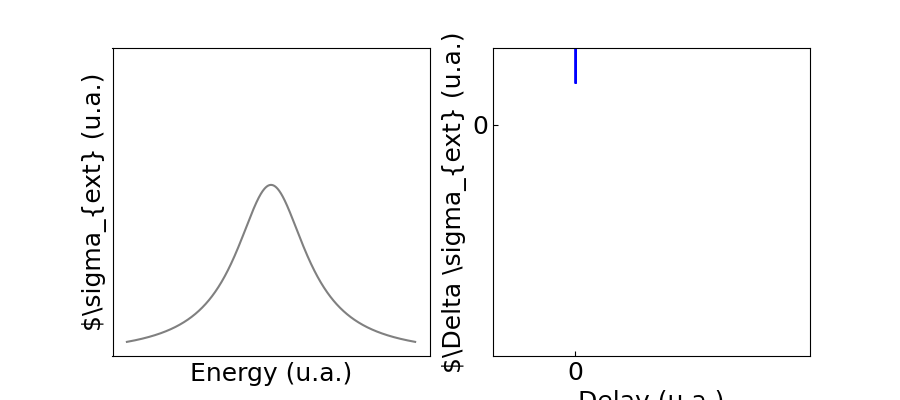

In [8]:
animation_name = 'SPR_and_DTT_signal_thermic'

fig, ax = plt.subplots(ncols=2, figsize=(9,4))


imax=100


#Set (x,y) limits for axes

ymin_spr, ymax_spr = 0,  6


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -1.5, 0.5
top_lim = 3
bottom_limit  = -0.5
Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.3
tau = 800/3

delta_Ec =0.1

#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0




ax[0].set_ylim((ymin_spr, ymax_spr))
ax[0].set_xticks([])  # Remove x-axis ticks
ax[0].set_yticks([])  # Remove y-axis ticks
ax[0].set_xlabel('Energy (u.a.)')
ax[0].set_ylabel(r'$\sigma_{ext} (u.a.)')


ax[1].set_ylim((ymin_dtt, ymax_dtt))
ax[1].set_xlim((xmin_dtt, xmax_dtt))
ax[1].set_xticks([0])  # Remove x-axis ticks
ax[1].set_yticks([0])  # Remove y-axis ticks
ax[1].set_xlabel('Delay (u.a.)')
ax[1].set_ylabel(r'$\Delta \sigma_{ext} (u.a.)')
ax[1].tick_params(direction='in')

scat = ax[0].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')

scat = ax[1].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')



Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
    ax[1].cla()
    ax[0].cla()
    x_probe = Energy[400]


    ### SPR plot 
    index_color = int(imax * (1- np.array(Time>0)[i]*(ExpDec1(Time[i], 1, tau)))-0.001)
    
    ax[0].set_ylim((ymin_spr, ymax_spr))
    ax[0].set_xticks([])  # Remove x-axis ticks
    ax[0].set_yticks([])  # Remove y-axis ticks
    ax[0].set_xlabel('Energy (u.a.)')
    ax[0].set_ylabel(r'$\sigma_{ext}$ (u.a.)')

    rect_disk = mpatches.Rectangle((0.65, 0.8), 0.2, 0.1, transform=ax[0].transAxes, facecolor=Colors[index_color].rgb, edgecolor='black')
    ax[0].add_patch(rect_disk)

    rect_sub = mpatches.Rectangle((0.55, 0.65), 0.4, 0.15, transform=ax[0].transAxes, facecolor='cyan',alpha=0.5, edgecolor='black')
    ax[0].add_patch(rect_sub)
    scat = ax[0].plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*(ExpDec1(Time[i], delta_Ec, tau)), w + np.array(Time>0)[i]*(ExpDec1(Time[i], delta_w, tau)), A, y0),color='blue')
    ax[0].plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)

    ax[0].plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(ExpDec1(Time[i], delta_Ec, tau)), w + np.array(Time>0)[i]*ExpDec1(Time[i], delta_w, tau), A, y0)], color='green')




    ## DTT plot
    ax[1].set_ylim((ymin_dtt, ymax_dtt))
    ax[1].set_xlim((xmin_dtt, xmax_dtt))
    ax[1].set_xticks([0])  # Remove x-axis ticks
    ax[1].set_yticks([0])  # Remove y-axis ticks
    ax[1].set_xlabel('Delay (u.a.)')
    ax[1].set_ylabel(r'$\Delta \sigma_{ext}$ (u.a.)')
    ax[1].tick_params(axis='x', direction='in', pad=-20)

    scat = ax[1].plot(Time[:i+1], Lorentz(x_probe, E_c+np.array(Time>0)[:i+1]*(ExpDec1(Time[:i+1], delta_Ec, tau)), w + np.array(Time>0)[:i+1]*ExpDec1(Time[:i+1], delta_w, tau), A, y0)-Lorentz(x_probe, E_c, w , A, y0),color='green')

 



    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()

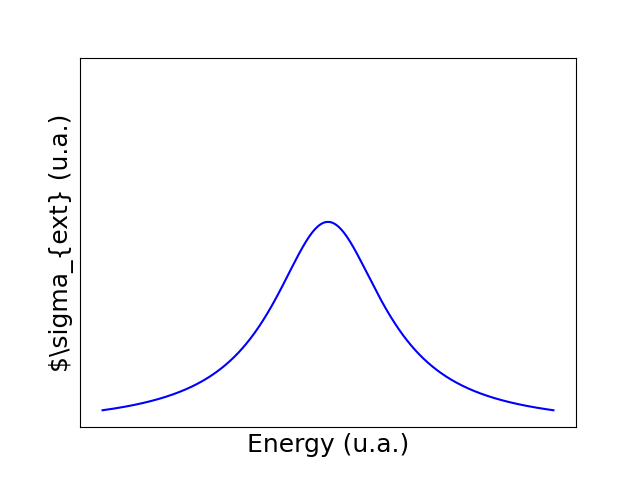

In [29]:
animation_name = 'SPR_signal_acoustic'

fig, ax = plt.subplots()


imax=100

ymin, ymax = 0, 6

Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)


#Variation on the SPR
delta_w = 0.05
delta_Ec =0.03

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient

#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0

ax.set_ylim((ymin, ymax))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks

plt.xlabel('Energy (u.a.)')
plt.ylabel(r'$\sigma_{ext} (u.a.)')

scat = ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')


Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :


    ax.cla()

    x_probe=Energy[400]

    ax.set_ylim((ymin, ymax))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('Energy (u.a.)')
    ax.set_ylabel(r'$\sigma_{ext}$ (u.a.)')


    width, height = 0.2, 0.1
    x_ini, y_ini = 0.85 - width/2, 0.85 - height/2

    x_c, y_c = x_ini - width/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi), y_ini - height/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)


    rect_disk = mpatches.Rectangle((x_c, y_c), 0.2*(1+ np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi) ), 0.1*(1+np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)), transform=ax.transAxes, facecolor='yellow', edgecolor='black')
    ax.add_patch(rect_disk)

    scat = ax.plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*Osc1(Time[i], delta_Ec, tau, T, phi), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0),color='blue')
    ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    ax.plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=False, frames=imax, interval = 10)
plt.show()


os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()

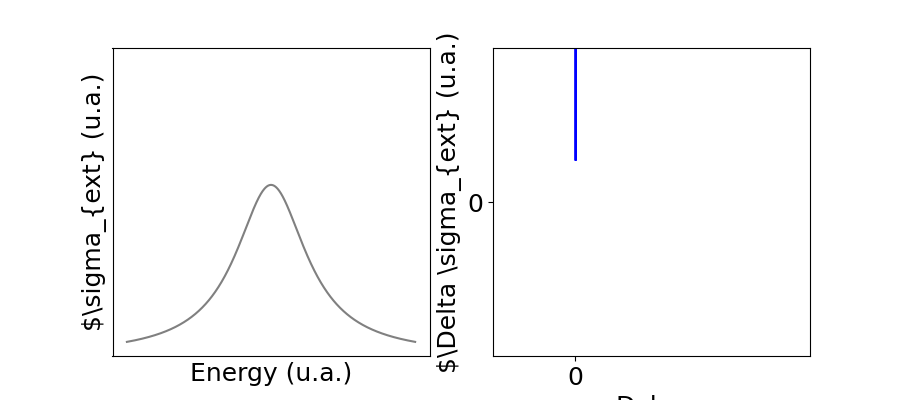

In [ ]:
animation_name = 'SPR_and_DTT_signal_acoustic'

fig, ax = plt.subplots(ncols=2, figsize=(9,4))


imax=100

#Set (x,y) limits for axes

ymin_spr, ymax_spr = (0,  6)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -1, 1

top_lim = 3
bottom_limit  = -0.5



Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.05
delta_Ec =0.03

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient


#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0




ax[0].set_ylim((ymin_spr, ymax_spr))
ax[0].set_xticks([])  # Remove x-axis ticks
ax[0].set_yticks([])  # Remove y-axis ticks
ax[0].set_xlabel('Energy (u.a.)')
ax[0].set_ylabel(r'$\sigma_{ext} (u.a.)')


ax[1].set_ylim((ymin_dtt, ymax_dtt))
ax[1].set_xlim((xmin_dtt, xmax_dtt))
ax[1].set_xticks([0])  # Remove x-axis ticks
ax[1].set_yticks([0])  # Remove y-axis ticks
ax[1].set_xlabel('Delay')
ax[1].set_ylabel(r'$\Delta \sigma_{ext} (u.a.)')


scat = ax[0].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')

scat = ax[1].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')



Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
    ax[1].cla()
    ax[0].cla()
    x_probe = Energy[400]


    ### SPR plot 

    ax[0].set_ylim((ymin_spr, ymax_spr))
    ax[0].set_xticks([])  # Remove x-axis ticks
    ax[0].set_yticks([])  # Remove y-axis ticks
    ax[0].set_xlabel('Energy (u.a.)')
    ax[0].set_ylabel(r'$\sigma_{ext}$ (u.a.)')

    width, height = 0.2, 0.1
    x_ini, y_ini = 0.85 - width/2, 0.85 - height/2
    x_c, y_c = x_ini - width/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi), y_ini - height/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)

    rect_disk = mpatches.Rectangle((x_c, y_c), 0.2*(1+ np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi) ), 0.1*(1+np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)), transform=ax[0].transAxes, facecolor='#ffc507ff', edgecolor='black')
    ax[0].add_patch(rect_disk)

    scat = ax[0].plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*Osc1(Time[i], delta_Ec, tau, T, phi), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0),color='blue')
    ax[0].plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    ax[0].plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')



    ## DTT plot
    ax[1].set_ylim((ymin_dtt, ymax_dtt))
    ax[1].set_xlim((xmin_dtt, xmax_dtt))
    ax[1].set_xticks([0])  # Remove x-axis ticks
    ax[1].set_yticks([0])  # Remove y-axis ticks
    ax[1].set_xlabel('Delay')
    ax[1].set_ylabel(r'$\Delta \sigma_{ext}$ (u.a.)')
    ax[1].tick_params(axis='x', direction='in', pad=-20)

    scat = ax[1].plot(Time[:i+1], Lorentz(x_probe, E_c+np.array(Time>0)[:i+1]*(Osc1(Time[:i+1], delta_Ec, tau, T, phi)), w + np.array(Time>0)[:i+1]*Osc1(Time[:i+1], delta_w, tau, T, phi), A, y0)-Lorentz(x_probe, E_c, w , A, y0),color='green')

 



    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(r'H:\commun\Utilisateur FNO\Nathan\Figures and illustrations\GIF')

if 1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()